<center><h1>HW4</h1></center>
<br>
<br>

Name: Naveed Alboudwarej
<br>
USC ID: 8695198359

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [23]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from ISLP.models import ModelSpec as MS,summarize
from ISLP import confusion_table
from sklearn.model_selection import StratifiedKFold,GridSearchCV,cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE,RFECV
from sklearn.naive_bayes import GaussianNB,MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import RocCurveDisplay,roc_auc_score

Get the AReM Data Set

In [2]:
root= os.path.join("AReM","AReM")
cols= ["time","avg_rss12","var_rss12","avg_rss13","var_rss13","avg_rss23","var_rss23"]
frames= []
for activity in os.listdir(root):
    folder= os.path.join(root,activity)
    if not os.path.isdir(folder):
        continue
    for file in os.listdir(folder):
        df= pd.read_csv(os.path.join(folder,file), skiprows= 5, names= cols, usecols= range(7), sep= r"[,\s]+", engine= "python")
        df["activity"]= activity
        df["dataset"]= int(file.replace("dataset","").replace(".csv",""))
        frames.append(df)
data= pd.concat(frames,ignore_index= True)
data.shape

(42239, 9)

### (b) Splitting Data

In [3]:
test_set= []
train_set= []
for (activity,num),df in data.groupby(["activity","dataset"]):
    if activity.startswith("bending"):
        max_test= 2
    else:
        max_test= 3
    if num<=max_test:
        test_set.append(df)
    else:
        train_set.append(df)
test_set= pd.concat(test_set)
train_set= pd.concat(train_set)

summary= pd.DataFrame({
    "Train":train_set.groupby("activity")["dataset"].nunique(),
    "Test":test_set.groupby("activity")["dataset"].nunique(),
    "All":data.groupby("activity")["dataset"].nunique()})
summary.loc["Total"]= summary.sum()
summary

,Train,Test,All
activity,,,
bending1,5,2,7
bending2,4,2,6
cycling,12,3,15
lying,12,3,15
sitting,12,3,15
standing,12,3,15
walking,12,3,15
Total,69,19,88


### (c) Feature Extraction

In [4]:
series= ["avg_rss12","var_rss12","avg_rss13","var_rss13","avg_rss23","var_rss23"]
row= data.groupby(["activity","dataset"])
features= pd.DataFrame(index= row.size().index)
for s in series:
    features[s+"_min"]= row[s].min()
    features[s+"_max"]= row[s].max()
    features[s+"_mean"]= row[s].mean()
    features[s+"_median"]= row[s].median()
    features[s+"_std"]= row[s].std()
    features[s+"_q1"]= row[s].quantile(0.25)
    features[s+"_q3"]= row[s].quantile(0.75)
features= features.reset_index()
print(features.shape)
features.head(10)

(88, 44)


,activity,dataset,avg_rss12_min,avg_rss12_max,avg_rss12_mean,avg_rss12_median,avg_rss12_std,avg_rss12_q1,avg_rss12_q3,var_rss12_min,...,avg_rss23_std,avg_rss23_q1,avg_rss23_q3,var_rss23_min,var_rss23_max,var_rss23_mean,var_rss23_median,var_rss23_std,var_rss23_q1,var_rss23_q3
0,bending1,1,37.25,45.00,40.624792,40.50,1.476967,39.2500,42.00,0.0,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.00,1.30
1,bending1,2,38.00,45.67,42.812812,42.50,1.435550,42.0000,43.67,0.0,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.00,1.30
2,bending1,3,35.00,47.40,43.954500,44.33,1.558835,43.0000,45.00,0.0,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94
3,bending1,4,33.00,47.75,42.179813,43.50,3.670666,39.1500,45.00,0.0,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00
4,bending1,5,33.00,45.75,41.678063,41.75,2.243490,41.3300,42.75,0.0,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50
5,bending1,6,37.00,48.00,43.454958,43.25,1.386098,42.5000,45.00,0.0,...,2.488862,22.2500,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87
6,bending1,7,36.25,48.00,43.969125,44.50,1.618364,43.3100,44.67,0.0,...,3.318301,20.5000,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83
7,bending2,1,12.75,51.00,24.562958,24.25,3.737514,23.1875,26.50,0.0,...,3.693786,20.5000,27.00,0.0,4.97,0.700187,0.50,0.693720,0.43,0.87
8,bending2,2,0.00,42.75,27.464604,28.00,3.583582,25.5000,30.00,0.0,...,5.053642,15.0000,20.75,0.0,6.76,1.122125,0.83,1.012342,0.47,1.30
9,bending2,3,21.00,50.00,32.586208,33.00,6.238143,26.1875,34.50,0.0,...,5.032424,17.6700,23.50,0.0,13.61,1.162042,0.83,1.332980,0.47,1.30


### (d) Feature Extraction Pt 2

In [5]:
x= features.drop(columns= ["activity","dataset"])
np.random.seed(0)
ci= []
for col in x.columns:
    values= x[col].values
    boot_std= []
    for i in range(1000):
        idx= np.random.choice(len(values),len(values),replace= True)
        boot_std.append(values[idx].std(ddof= 1))
    ci.append([col,values.std(ddof= 1),np.percentile(boot_std,5),np.percentile(boot_std,95)])
ci= pd.DataFrame(ci,columns= ["feature","std","lower_5%","upper_95%"]).set_index("feature").round(3)
ci["width_%"]= ((ci["upper_95%"]-ci["lower_5%"])/ci["std"]*100).round(0)
ci

,std,lower_5%,upper_95%,width_%
feature,,,,
avg_rss12_min,9.570,8.266,10.784,26.0
avg_rss12_max,4.394,3.325,5.281,45.0
avg_rss12_mean,5.336,4.706,5.863,22.0
avg_rss12_median,5.440,4.777,6.022,23.0
avg_rss12_std,1.772,1.573,1.954,22.0
avg_rss12_q1,6.154,5.565,6.626,17.0
avg_rss12_q3,5.139,4.325,5.837,29.0
var_rss12_min,0.000,0.000,0.000,NaN
var_rss12_max,5.063,4.626,5.394,15.0


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

(69, 45)
bending
False    60
True      9
Name: count, dtype: int64


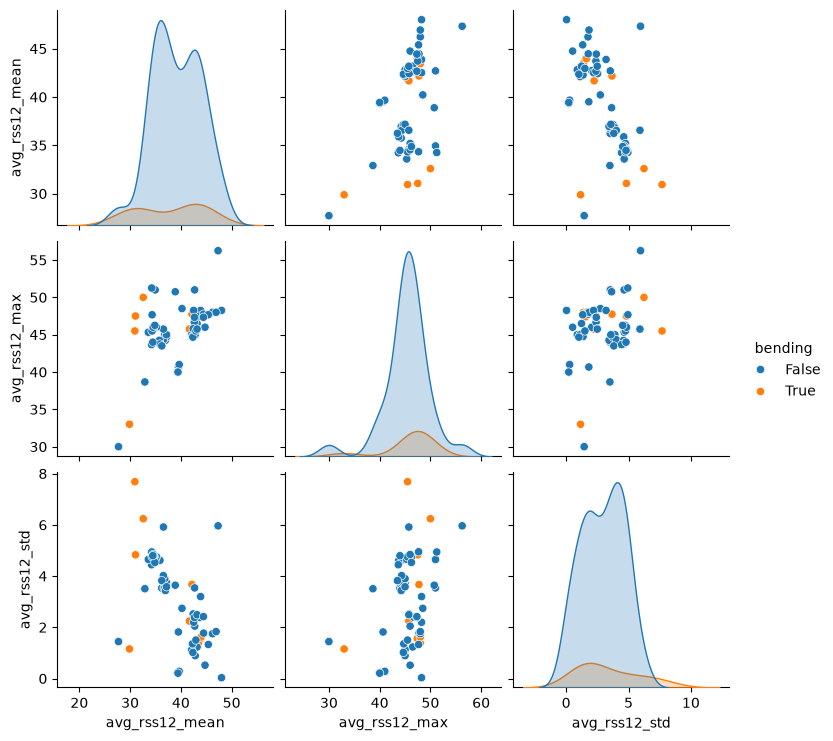

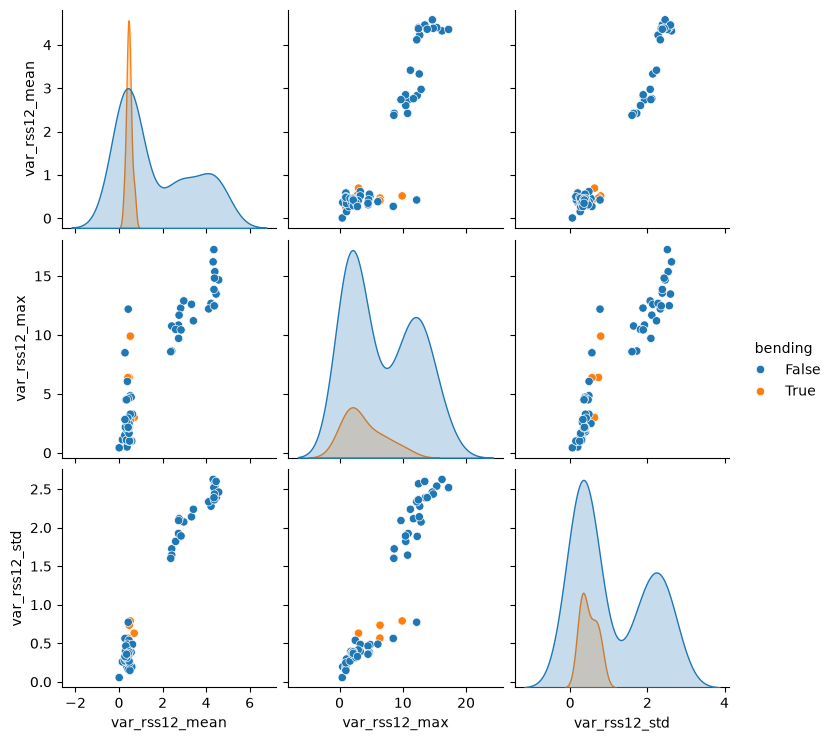

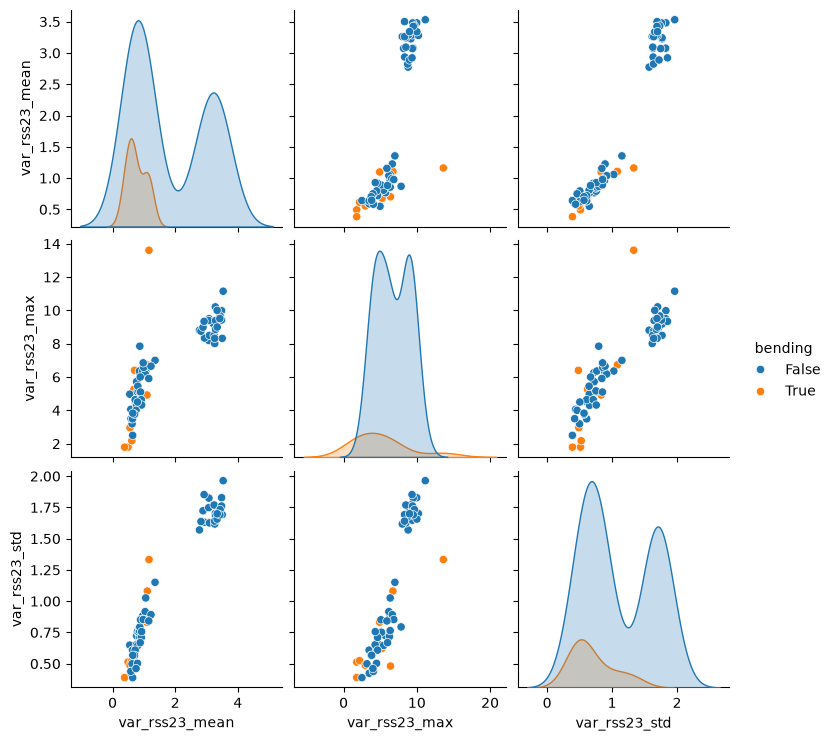

In [6]:
train_keys= train_set[["activity","dataset"]].drop_duplicates()
train= features.merge(train_keys)
train["bending"]= train["activity"].isin(["bending1","bending2"])
print(train.shape)
print(train["bending"].value_counts())

for s in ["avg_rss12","var_rss12","var_rss23"]:
    sns.pairplot(train,vars= [s+"_mean",s+"_max",s+"_std"],hue= "bending")
    plt.show()

Bending is only 9 of the 69 training instances. In the avg_rss12 plots it is spread through the same cloud as the other activities, with some of the largest standard deviations. In the var_rss12 and var_rss23 plots it sits at the low-variance end, where many other activities also sit, while the high-variance group is entirely other activities. No pair of features separates bending cleanly.

#### ii. Splitted Plots

(69, 39)


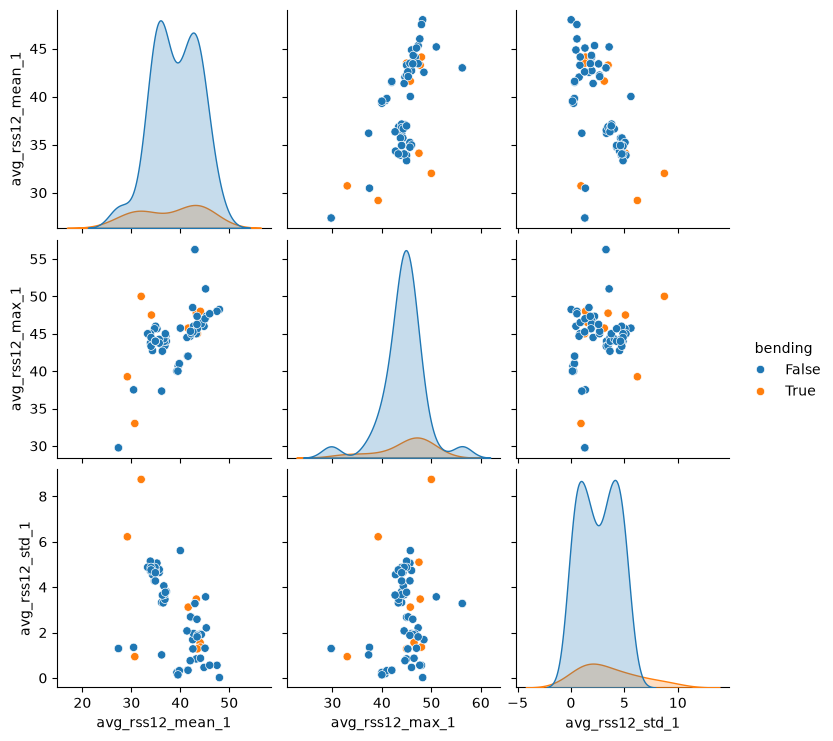

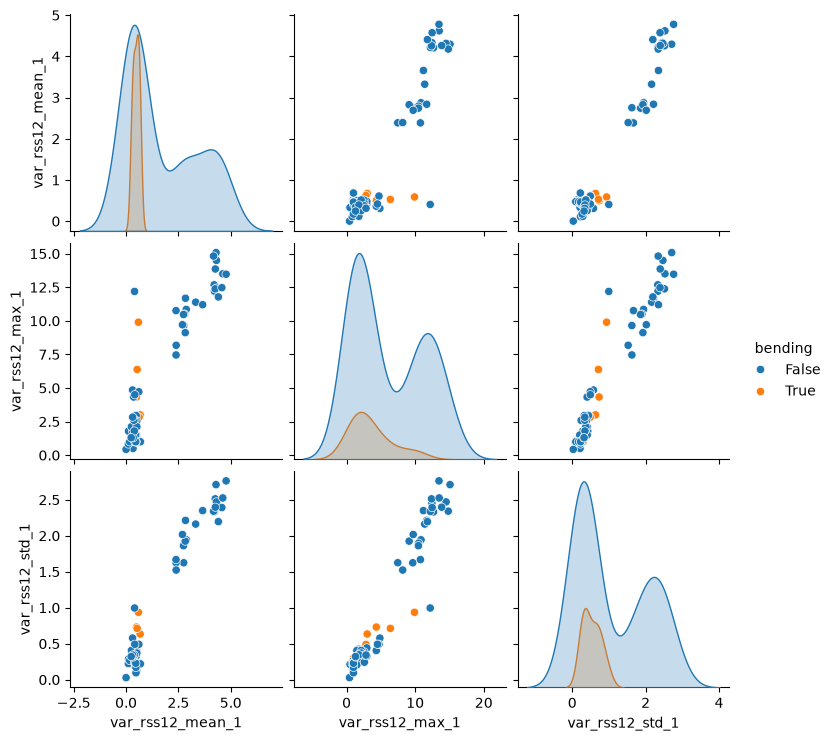

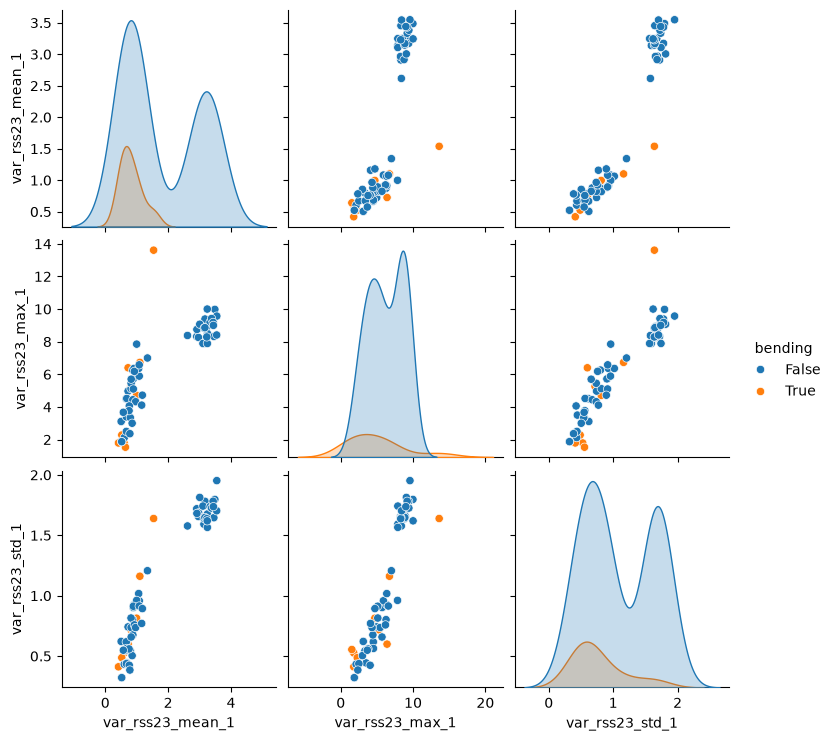

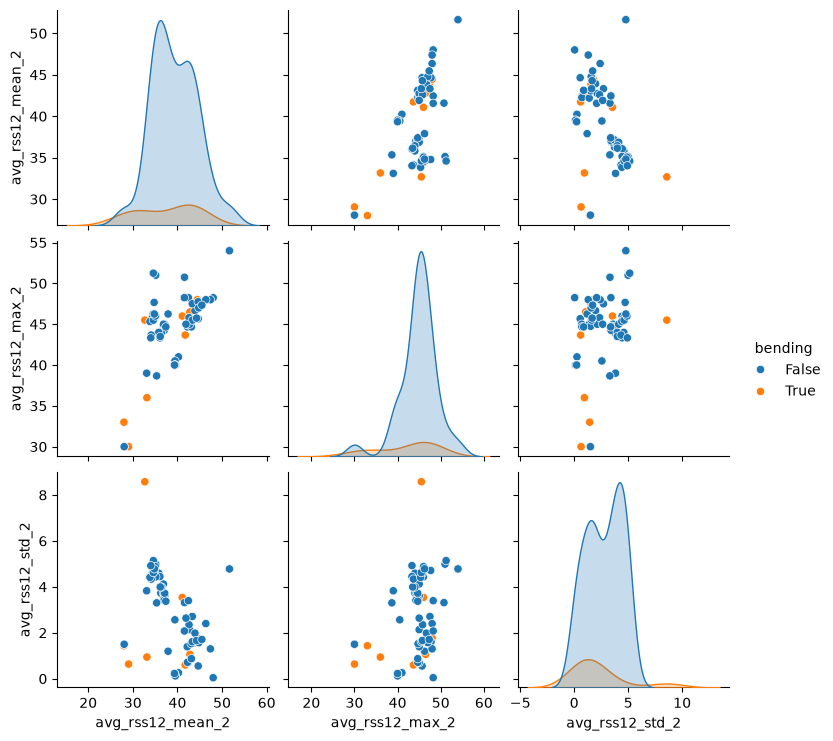

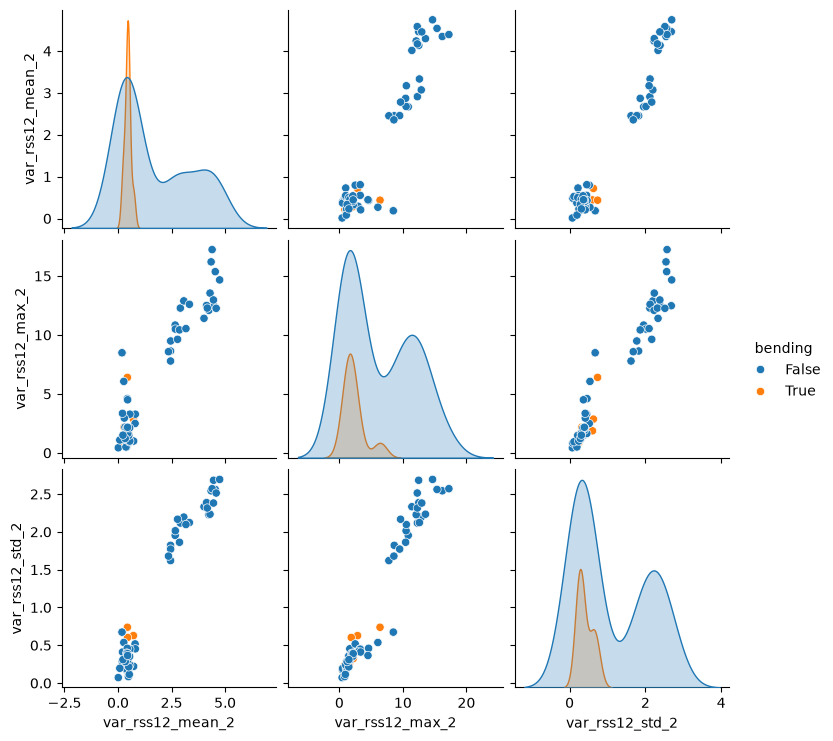

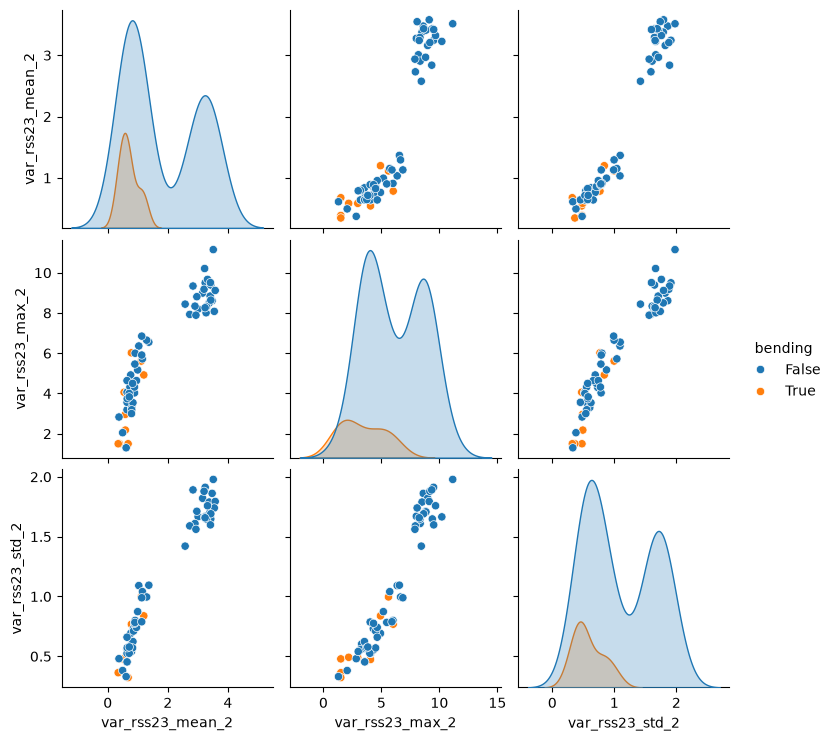

In [7]:
def split_features(frame,l):
    frame= frame.copy()
    key= frame.groupby(["activity","dataset"])
    frame["piece"]= key.cumcount()*l//key["time"].transform("size")+1
    row= frame.groupby(["activity","dataset","piece"])
    out= pd.DataFrame(index= row.size().index)
    for s in series:
        out[s+"_max"]= row[s].max()
        out[s+"_mean"]= row[s].mean()
        out[s+"_std"]= row[s].std()
    out= out.unstack("piece")
    out.columns= [name+"_"+str(p) for name,p in out.columns]
    return out.reset_index()

train_half= split_features(train_set,2)
train_half["bending"]= train_half["activity"].isin(["bending1","bending2"])
print(train_half.shape)

for k in ["1","2"]:
    for s in ["avg_rss12","var_rss12","var_rss23"]:
        sns.pairplot(train_half,vars= [s+"_mean_"+k,s+"_max_"+k,s+"_std_"+k],hue= "bending")
        plt.show()

The plots for each half look very similar to the full-series plots in 2(a)i. Bending still overlaps with the other activities in both halves, so I don't see a considerable difference.

#### iii. Time Series Segments

In [8]:
skf= StratifiedKFold(n_splits= 5,shuffle= True,random_state= 0)
pipe= Pipeline(steps= [("scaler",StandardScaler()),("logit",LogisticRegression(C= 1e6,max_iter= 1000))])
frames= []
for l in range(1,21):
    train_l= split_features(train_set,l)
    y= train_l["activity"].isin(["bending1","bending2"])
    X= train_l.drop(columns= ["activity","dataset"])
    rfecv= RFECV(pipe,cv= skf,importance_getter= "named_steps.logit.coef_",n_jobs= -1).fit(X,y)
    scores= rfecv.cv_results_["mean_test_score"]
    frames.append(pd.DataFrame({"l":l,"p":range(1,len(scores)+1),"accuracy":scores}))
results= pd.concat(frames,ignore_index= True)
results.sort_values(["accuracy","l","p"],ascending= [False,True,True]).head(10)

,l,p,accuracy
3089,19,12,0.984615
3090,19,13,0.984615
3092,19,15,0.984615
3093,19,16,0.984615
3095,19,18,0.984615
3,1,4,0.971429
25,2,8,0.971429
26,2,9,0.971429
1405,13,2,0.971429
824,10,15,0.970330


In [9]:
best= results.loc[results["accuracy"].idxmax()]
best

l           19.000000
p           12.000000
accuracy     0.984615
Name: 3089, dtype: float64

For each l from 1 to 20 I split every series into l pieces, took the mean, max and std of each piece, and used RFECV with a scaled logistic regression and stratified 5-fold cross-validation to choose the number of features p. The best pair was l= 19, p= 12 with a CV accuracy of 0.985 (several values of p at l= 19 tie, and I took the first). The best l= 1 model reached 0.971, so splitting the series helped only slightly. The right way to cross-validate is to do the scaling and feature selection inside each training fold and score on the held-out fold, which RFECV with a pipeline does. The wrong way is to select features on all the data first and then cross-validate, because the held-out folds have already influenced the choice, which makes the accuracy too optimistic. Stratified folds make sure every fold contains some of the 9 bending instances.

#### iv. Confusion Matrix

In [10]:
l= int(best["l"])
p= int(best["p"])
train_l= split_features(train_set,l)
y= train_l["activity"].isin(["bending1","bending2"])
X= train_l.drop(columns= ["activity","dataset"])
rfe= RFE(pipe,n_features_to_select= p,importance_getter= "named_steps.logit.coef_").fit(X,y)
chosen= list(X.columns[rfe.support_])

X_sel= MS(chosen).fit_transform(train_l)
glm= sm.GLM(y,X_sel,family= sm.families.Binomial()).fit(maxiter= 5)
summarize(glm)

,coef,std err,z,P>|z|
intercept,0.3016,17.187,0.018,0.986
avg_rss12_mean_12,0.1038,1.572,0.066,0.947
avg_rss12_mean_14,-0.3836,1.584,-0.242,0.809
avg_rss13_std_9,-0.6591,1.649,-0.400,0.689
var_rss13_max_14,-0.5055,1.448,-0.349,0.727
avg_rss23_max_1,0.1049,0.625,0.168,0.867
avg_rss23_max_3,-0.3381,1.401,-0.241,0.809
avg_rss23_max_6,0.1421,0.962,0.148,0.883
avg_rss23_mean_3,0.7447,1.451,0.513,0.608
avg_rss23_mean_6,0.0265,1.048,0.025,0.980


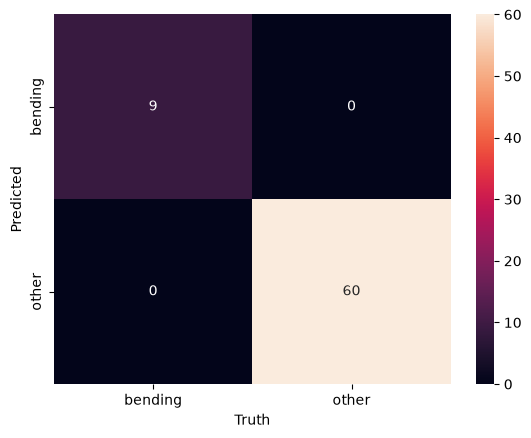

In [11]:
probs= glm.predict()
labels= np.where(probs>0.5,"bending","other")
cm= confusion_table(labels,np.where(y,"bending","other"))
sns.heatmap(cm,annot= True,fmt= "d")
plt.show()

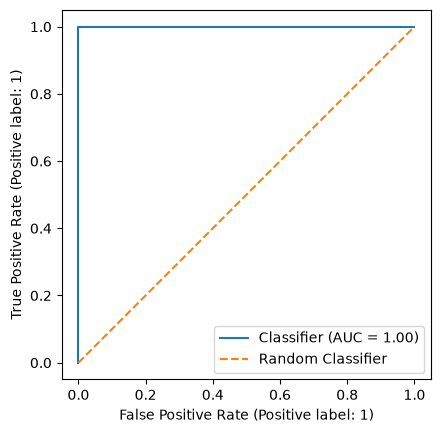

1.0

In [12]:
RocCurveDisplay.from_predictions(y,probs)
plt.plot([0,1],[0,1],"--",label= "Random Classifier")
plt.xlim(-0.05,1.05)
plt.ylim(-0.05,1.05)
plt.legend()
plt.show()
roc_auc_score(y,probs)

With l= 19 and p= 12, RFE kept 12 features, mostly from avg_rss23 plus a few from avg_rss12, avg_rss13, var_rss13 and var_rss23. On the training set all 69 instances are classified correctly (9 bending, 60 other) and the AUC is 1.0. No coefficient is significant: the smallest p-value is 0.425, and the standard errors are large (17.2 for the intercept). These p-values should be treated with caution because the classes are separated (see vi).

#### v. Test Classifier

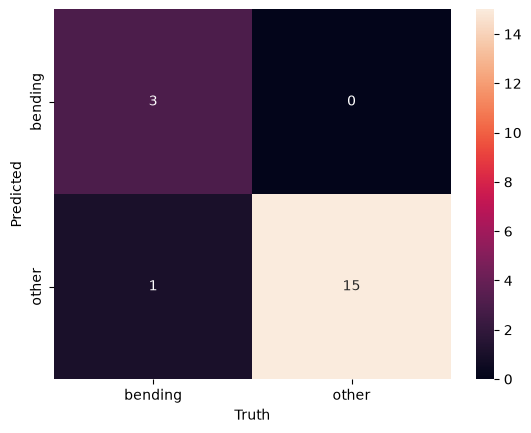

Test accuracy: 0.9473684210526315
CV accuracy: 0.9846153846153847


In [13]:
test_l= split_features(test_set,l)
y_test= test_l["activity"].isin(["bending1","bending2"])
X_test= MS(chosen).fit_transform(test_l)
probs_test= glm.predict(X_test)
labels_test= np.where(probs_test>0.5,"bending","other")
truth_test= np.where(y_test,"bending","other")
sns.heatmap(confusion_table(labels_test,truth_test),annot= True,fmt= "d")
plt.show()

test_accuracy= np.mean(labels_test==truth_test)
print("Test accuracy:",test_accuracy)
print("CV accuracy:",best["accuracy"])

On the test set the confusion matrix is 3 bending and 15 other correct, with 1 false negative (a bending instance predicted as other) and no false positives. The test accuracy is 0.947, a little lower than the cross-validation accuracy of 0.985. That is expected: the CV score is the best of many (l, p) choices, and the test set has only 19 instances, so each mistake costs about 5 points. It is still better than always predicting "other", which would give 0.789.

#### vi. Separation

Yes, the classes look well-separated. On the training data every instance was classified correctly (9 bending and 60 other) and the AUC was 1.0, so a line can split the two classes perfectly. That makes the logistic regression unstable, because the coefficients keep growing without settling, so the coefficients and p-values aren’t reliable.

#### vii. Imbalance

In [14]:
cases= X_sel[y==1]
controls= X_sel[y==0].sample(len(cases),random_state= 0)
X_cc= pd.concat([cases,controls])
y_cc= y[X_cc.index]
glm_cc= sm.GLM(y_cc,X_cc,family= sm.families.Binomial()).fit(maxiter= 5)
params_cc= glm_cc.params.copy()
params_cc["intercept"]= params_cc["intercept"]+np.log(y.mean()/(1-y.mean()))
params_cc

intercept            10.289628
avg_rss12_mean_12     0.476244
avg_rss12_mean_14    -0.877401
avg_rss13_std_9      -1.271824
var_rss13_max_14     -0.504907
avg_rss23_max_1       0.266853
avg_rss23_max_3      -0.687035
avg_rss23_max_6      -0.504467
avg_rss23_mean_3      0.800879
avg_rss23_mean_6      0.668644
avg_rss23_std_18     -2.073450
avg_rss23_std_19      1.748924
var_rss23_std_15     -0.247807
dtype: float64

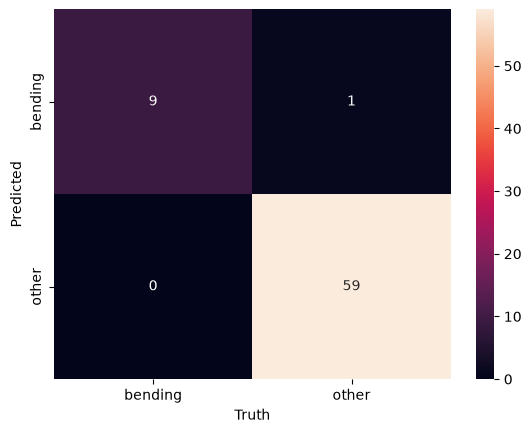

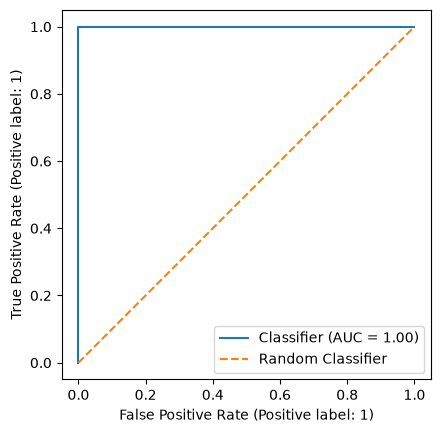

0.9999999999999999

In [15]:
probs_cc= glm_cc.model.predict(params_cc,X_sel)
labels_cc= np.where(probs_cc>0.5,"bending","other")
sns.heatmap(confusion_table(labels_cc,np.where(y,"bending","other")),annot= True,fmt= "d")
plt.show()

RocCurveDisplay.from_predictions(y,probs_cc)
plt.plot([0,1],[0,1],"--",label= "Random Classifier")
plt.xlim(-0.05,1.05)
plt.ylim(-0.05,1.05)
plt.legend()
plt.show()
roc_auc_score(y,probs_cc)

Yes, the classes are imbalanced: 60 non-bending against 9 bending instances in training (13% bending). I used case-control sampling, keeping all 9 bending instances plus 9 randomly chosen others, refit the model, and corrected the intercept by adding log(π/(1−π)) with π= 9/69. The corrected model has 9 true positives, 59 true negatives, 1 false positive and 0 false negatives on the training set, with an AUC of 1.0. That is the same AUC as the original model, with one new false alarm and no missed bending instances.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [16]:
pipe_l1= Pipeline(steps= [("scaler",StandardScaler()),("logit",LogisticRegression(l1_ratio= 1,solver= "liblinear"))])
param_grid= {"logit__C":np.logspace(-3,2,20)}
rows= []
for l in range(1,21):
    train_l= split_features(train_set,l)
    y= train_l["activity"].isin(["bending1","bending2"])
    X= train_l.drop(columns= ["activity","dataset"])
    gs= GridSearchCV(pipe_l1,param_grid,cv= skf).fit(X,y)
    rows.append([l,gs.best_params_["logit__C"],gs.best_score_])
results_l1= pd.DataFrame(rows,columns= ["l","C","accuracy"])
results_l1.sort_values(["accuracy","l"],ascending= [False,True]).head(10)
best_l1= results_l1.loc[results_l1["accuracy"].idxmax()]
best_l1

l           12.000000
C            0.784760
accuracy     0.985714
Name: 11, dtype: float64

In [17]:
l= int(best_l1["l"])
train_l= split_features(train_set,l)
test_l= split_features(test_set,l)
y= train_l["activity"].isin(["bending1","bending2"])
y_test= test_l["activity"].isin(["bending1","bending2"])
X= train_l.drop(columns= ["activity","dataset"])
X_test= test_l.drop(columns= ["activity","dataset"])
pipe_l1.set_params(logit__C= best_l1["C"]).fit(X,y)
pipe_l1.score(X_test,y_test)

0.9473684210526315

I used L1-penalized logistic regression and cross-validated both l and the penalty. The best values were l= 12 and C= 0.785, with a CV accuracy of 0.986. On the test set the accuracy was 0.947 (18 of 19 correct).

#### ii. Comparison

The two methods performed the same. The best cross-validation accuracy was 0.986 for L1 (l= 12, C= 0.785, with 5 of 216 features kept) and 0.985 for the p-value method (l= 19, p= 12). On the test set both got 0.947 (18 of 19 correct), and both missed the same one bending instance.

L1 is easier to implement. It is one model with one setting to tune, C, which cross-validation handles in a single step, and it selects the features by itself. The p-value method needs more steps: RFE inside cross-validation, a refit on the chosen features, and a separate GLM to get the p-values. Those p-values are not reliable here because the classes are separated, and none is below 0.4 in the final model.

**Conclusion:** The two methods perform the same, and L1-penalized logistic regression is easier to implement.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [18]:
pipe_m= Pipeline(steps= [("scaler",StandardScaler()),("logit",LogisticRegression(l1_ratio= 1,solver= "saga",max_iter= 5000))])
param_grid= {"logit__C":np.logspace(-2,2,10)}
rows= []
for l in range(1,21):
    train_l= split_features(train_set,l)
    y= train_l["activity"]
    X= train_l.drop(columns= ["activity","dataset"])
    gs= GridSearchCV(pipe_m,param_grid,cv= skf,n_jobs= -1).fit(X,y)
    rows.append([l,gs.best_params_["logit__C"],gs.best_score_])
results_m= pd.DataFrame(rows,columns= ["l","C","accuracy"])
results_m.sort_values(["accuracy","l"],ascending= [False,True]).head(10)
best_m= results_m.loc[results_m["accuracy"].idxmax()]
best_m

l           1.000000
C           1.668101
accuracy    0.897802
Name: 0, dtype: float64

Test error: 0.10526315789473684


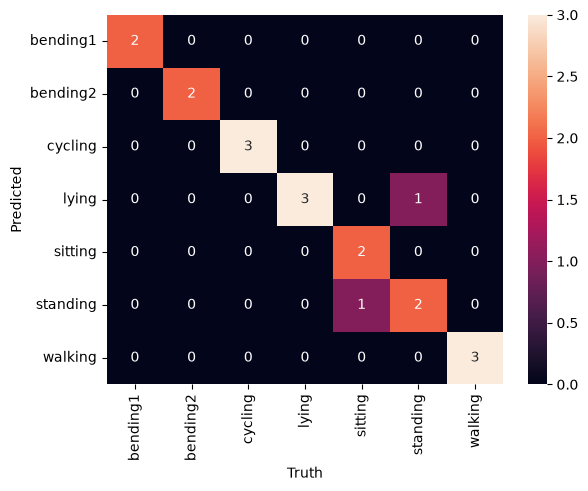

In [19]:
l= int(best_m["l"])
train_l= split_features(train_set,l)
test_l= split_features(test_set,l)
y= train_l["activity"]
y_test= test_l["activity"]
X= train_l.drop(columns= ["activity","dataset"])
X_test= test_l.drop(columns= ["activity","dataset"])
pipe_m.set_params(logit__C= best_m["C"]).fit(X,y)
pred= pipe_m.predict(X_test)
print("Test error:",1-np.mean(pred==y_test))
sns.heatmap(confusion_table(pred,y_test),annot= True,fmt= "d")
plt.show()

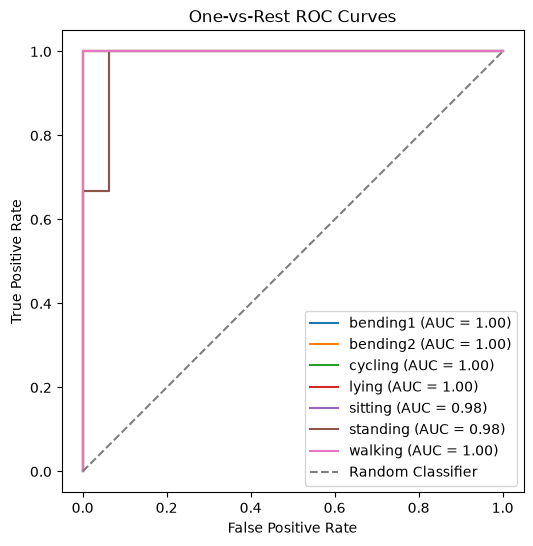

0.9940476190476192

In [20]:
probs= pipe_m.predict_proba(X_test)
fig,ax= plt.subplots(figsize= (7,6))
for i,c in enumerate(pipe_m.classes_):
    RocCurveDisplay.from_predictions(y_test==c,probs[:,i],ax= ax,name= c)
ax.plot([0,1],[0,1],"--",label= "Random Classifier")
ax.set_xlim(-0.05,1.05)
ax.set_ylim(-0.05,1.05)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("One-vs-Rest ROC Curves")
ax.legend(loc= "lower right")
plt.show()
roc_auc_score(y_test,probs,multi_class= "ovr")

I used multinomial logistic regression with an L1 penalty and cross-validated l and C. The best values were l = 1 and C = 1.668, with a CV accuracy of 0.898. The test error is 0.105 (2 of 19 misclassified), and the average one-vs-rest AUC is 0.994.

For multiclass problems, the confusion matrix is a 7x7 table of predicted vs. true activities, and the ROC curve is defined one-vs-rest: each activity gets its own curve, treating that activity as positive and all others as negative, and the AUC is averaged over the seven curves.

**Conclusion:** The multinomial L1 model separates the seven activities well, with a test error of 0.105 and an AUC close to 1.

#### ii. Naive Bayes

In [21]:
nb_models= {"Gaussian":GaussianNB(),"Multinomial":MultinomialNB()}
rows= []
for l in range(1,21):
    train_l= split_features(train_set,l)
    y= train_l["activity"]
    X= train_l.drop(columns= ["activity","dataset"])
    for name,nb in nb_models.items():
        rows.append([name,l,cross_val_score(nb,X,y,cv= skf).mean()])
results_nb= pd.DataFrame(rows,columns= ["model","l","accuracy"])
acc= results_nb.pivot(index= "l",columns= "model",values= "accuracy")
best_l= acc.idxmax()
pd.DataFrame({"best l":best_l,"CV accuracy":acc.max()})

,best l,CV accuracy
model,,
Gaussian,1,0.853846
Multinomial,11,0.871429


Gaussian Test error: 0.10526315789473684


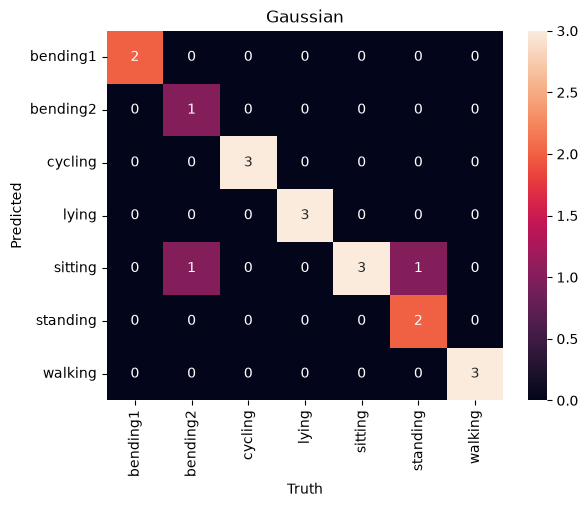

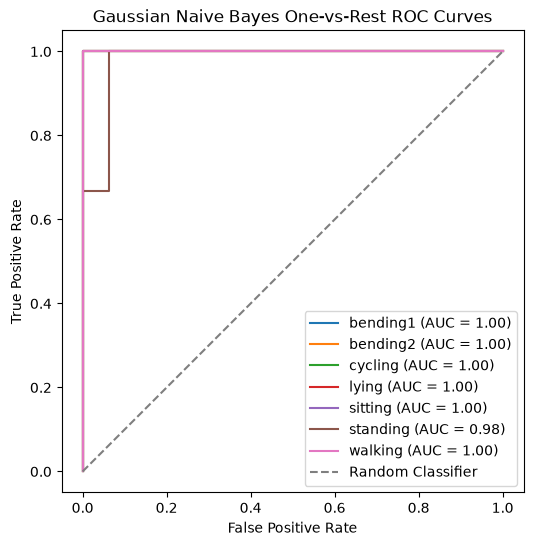

Gaussian AUC: 0.9970238095238095
Multinomial Test error: 0.052631578947368474


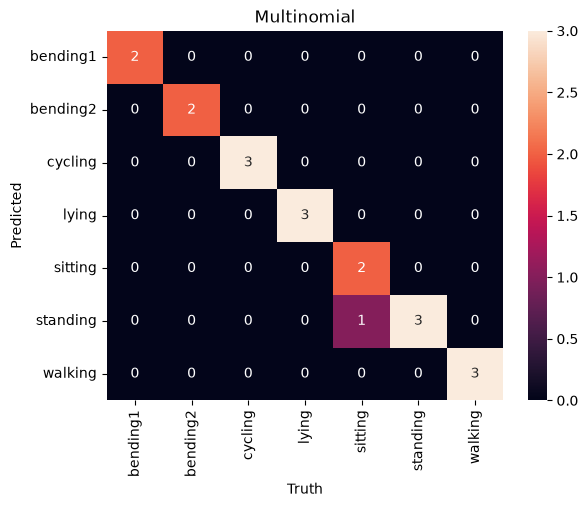

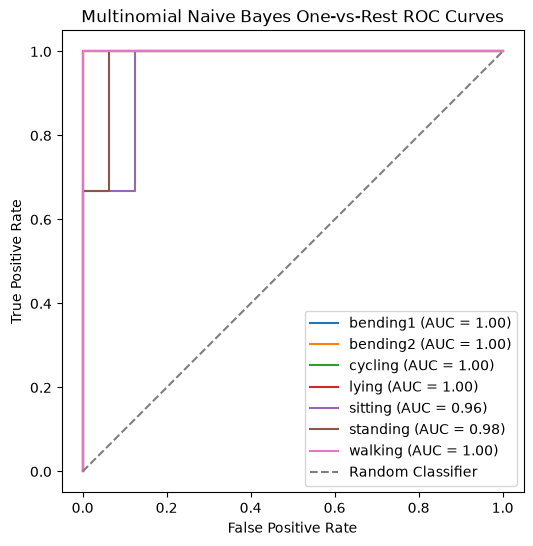

Multinomial AUC: 0.9910714285714286


In [22]:
for name,nb in nb_models.items():
    l= best_l[name]
    train_l= split_features(train_set,l)
    test_l= split_features(test_set,l)
    y= train_l["activity"]
    y_test= test_l["activity"]
    X= train_l.drop(columns= ["activity","dataset"])
    X_test= test_l.drop(columns= ["activity","dataset"])
    nb.fit(X,y)
    pred= nb.predict(X_test)
    print(name,"Test error:",1-np.mean(pred==y_test))
    sns.heatmap(confusion_table(pred,y_test),annot= True,fmt= "d")
    plt.title(name)
    plt.show()
    probs= nb.predict_proba(X_test)
    fig,ax= plt.subplots(figsize= (7,6))
    for i,c in enumerate(nb.classes_):
        RocCurveDisplay.from_predictions(y_test==c,probs[:,i],ax= ax,name= c)
    ax.plot([0,1],[0,1],"--",label= "Random Classifier")
    ax.set_xlim(-0.05,1.05)
    ax.set_ylim(-0.05,1.05)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(name+" Naive Bayes One-vs-Rest ROC Curves")
    ax.legend(loc= "lower right")
    plt.show()
    print(name,"AUC:",roc_auc_score(y_test,probs,multi_class= "ovr"))

I fit Gaussian and multinomial Naive Bayes and cross-validated l for each. The multinomial version works here because the mean, max and std features are all non-negative.

| Model | Best l | CV accuracy | Test error | AUC |
|---|---|---|---|---|
| Gaussian NB | 1 | 0.854 | 0.105 | 0.997 |
| Multinomial NB | 11 | 0.871 | 0.053 | 0.991 |
| L1 multinomial regression | 1 | 0.898 | 0.105 | 0.994 |

The test set has only 19 instances, so the gap between Gaussian and multinomial Naive Bayes is one misclassified instance.

**Conclusion:** Multinomial Naive Bayes performed slightly better than Gaussian Naive Bayes (test error 0.053 against 0.105).

#### iii. Which Method Is Better

The L1-penalized multinomial logistic regression is the better method. It had the highest cross-validation accuracy (0.898 vs. 0.854 for Gaussian and 0.871 for Multinomial Naive Bayes), and cross-validation uses all 69 training instances, so it is a more reliable measure than the 19-instance test set. On the test set, L1 and Gaussian Naive Bayes both had an error of 0.105 and Multinomial Naive Bayes had 0.053, but that is a difference of only one instance.

Naive Bayes is simpler and faster, with no parameter to tune, but it assumes the features are independent, which is unlikely here because the mean, max, and standard deviation of the same series are strongly related. L1 regression does not make that assumption and also selects features on its own.

## 3. ISLR 4.8.3

Answer: Let $\pi_k=P(Y=k)$ be the prior probability that an observation belongs to class $k$. For class $k$, the density of $X$ is

$$f_k(x)=\frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)$$

By Bayes' theorem, the posterior probability is

$$p_k(x)=\frac{\pi_k f_k(x)}{\sum_{l=1}^{K}\pi_l f_l(x)}$$

The Bayes classifier assigns $x$ to the class with the largest $p_k(x)$. The denominator is the same for every class and the log is increasing, so this is the class with the largest

$$\delta_k(x)=-\frac{1}{2\sigma_k^2}x^2+\frac{\mu_k}{\sigma_k^2}x-\frac{\mu_k^2}{2\sigma_k^2}-\log\sigma_k+\log\pi_k$$

(the constant $-\tfrac{1}{2}\log(2\pi)$ is the same for all classes, so it is dropped). In Section 4.4.1 the variances are equal, so the $x^2$ term is the same for every class and cancels, which leaves a linear function of $x$. Here each class has its own $\sigma_k^2$, so the $x^2$ term does not cancel.

**Conclusion:** Because $\delta_k(x)$ contains an $x^2$ term, the Bayes classifier is not linear. It is quadratic whenever the class variances differ, and equal variances reduce it to the linear LDA boundary.

## 4. ISLR 4.8.7

Answer: Let $Y$ be whether a company issues a dividend. The priors are $\pi_{\text{yes}}=0.8$ and $\pi_{\text{no}}=0.2$, the class means are $\hat\mu_{\text{yes}}=10$ and $\hat\mu_{\text{no}}=0$, and the common variance is $\hat\sigma^2=36$. By Bayes' theorem,

$$P(Y=\text{yes}\mid X=4)=\frac{\pi_{\text{yes}}f_{\text{yes}}(4)}{\pi_{\text{yes}}f_{\text{yes}}(4)+\pi_{\text{no}}f_{\text{no}}(4)}$$

Both classes have the same variance, so the factor $\frac{1}{\sqrt{2\pi\cdot 36}}$ cancels, and

$$P(Y=\text{yes}\mid X=4)=\frac{0.8\,e^{-(4-10)^2/(2\cdot 36)}}{0.8\,e^{-(4-10)^2/(2\cdot 36)}+0.2\,e^{-(4-0)^2/(2\cdot 36)}}=\frac{0.8\,e^{-0.5}}{0.8\,e^{-0.5}+0.2\,e^{-0.222}}\approx\frac{0.485}{0.485+0.160}\approx 0.752$$

**Conclusion:** A company with a last-year profit of $X=4\%$ has a predicted probability of about $0.752$ (75.2%) of issuing a dividend this year.